In [14]:
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt


In [15]:
df = pd.read_csv("Wine.csv")

In [16]:
df.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


In [17]:
df.keys()

Index(['Alcohol', 'Malic_Acid', 'Ash', 'Ash_Alcanity', 'Magnesium',
       'Total_Phenols', 'Flavanoids', 'Nonflavanoid_Phenols',
       'Proanthocyanins', 'Color_Intensity', 'Hue', 'OD280', 'Proline',
       'Customer_Segment'],
      dtype='object')

In [18]:
df['Customer_Segment'].unique()

array([1, 2, 3])

In [19]:
print(df.isnull().sum())

Alcohol                 0
Malic_Acid              0
Ash                     0
Ash_Alcanity            0
Magnesium               0
Total_Phenols           0
Flavanoids              0
Nonflavanoid_Phenols    0
Proanthocyanins         0
Color_Intensity         0
Hue                     0
OD280                   0
Proline                 0
Customer_Segment        0
dtype: int64


In [20]:
X = df.drop('Customer_Segment', axis=1)
y = df['Customer_Segment']

In [21]:
sc = StandardScaler()
X = sc.fit_transform(X)

In [22]:
pca = PCA()
X_pca = pca.fit_transform(X)

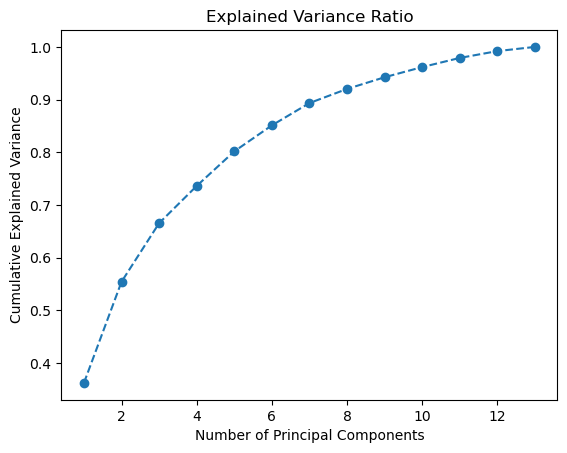

In [23]:
explained_variance_ratio = pca.explained_variance_ratio_

plt.plot(
    range(1, len(explained_variance_ratio) + 1),
    explained_variance_ratio.cumsum(),
    marker='o',
    linestyle='--'
)

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance Ratio')
plt.show()

In [24]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

In [25]:
print("Original shape:", X.shape)
print("PCA shape:", X_pca.shape)

Original shape: (178, 13)
PCA shape: (178, 2)


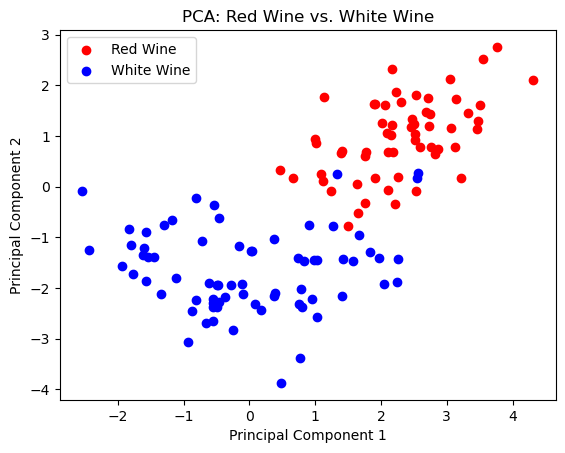

In [26]:
red_indices = y[y == 1].index
white_indices = y[y == 2].index

plt.scatter(
    X_pca[red_indices, 0],
    X_pca[red_indices, 1],
    c='red',
    label='Red Wine'
)

plt.scatter(
    X_pca[white_indices, 0],
    X_pca[white_indices, 1],
    c='blue',
    label='White Wine'
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.title('PCA: Red Wine vs. White Wine')
plt.show()